# Comparación de ARGus entrenado al 95 % y al 99 % de identidad

Este notebook reúne los resultados de cambiar el umbral de agrupamiento de CD-HIT
de 95 % a 99 % de identidad, para las dos etapas del sistema.

El cambio se hizo porque al 95 % muchas variantes de un mismo gen quedaban
colapsadas en un solo representante, y varias familias de resistencia se quedaban
con tan pocos ejemplos que no alcanzaban el mínimo para ser modeladas. Subir a
99 % conserva más variantes: el conjunto de positivos pasó de 4,228 a 6,257
secuencias.

**Qué hace este notebook y qué no.** No entrena nada. Lee los archivos de
predicciones y los metadatos que dejaron los scripts de entrenamiento, y los pone
uno al lado del otro. Los modelos se entrenan con:

| etapa | script |
|---|---|
| 1 — detección binaria | `scripts/reentrenar_fragmentacion.py --identidad 99 --guardar-tsv` |
| 2 — familia, RandomForest | `scripts/modelo_familias.py --min-clase 30 --sin-otras` |
| 2 — familia, DNABERT-6 | `scripts/familias_dnabert.py` |

Las cuatro configuraciones del modelo binario que se comparan aquí son:

- **90 %** y **95 %**, las anteriores
- **99 % completo**, con las 6,257 secuencias
- **99 % sin parientes**, con 4,450 — se le quitaron los 808 positivos que tienen
  un pariente al 95 % o más dentro del conjunto de evaluación, para medir cuánto
  del resultado venía de entrenar con casi copias de lo que después se evalúa

Las cuatro se miden sobre el mismo conjunto fijo de 1,000 positivos y 1,000
negativos, que nunca entra al entrenamiento.

## 0. Carga

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (average_precision_score, precision_recall_curve,
                             roc_auc_score, roc_curve)

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"font.size": 9, "axes.linewidth": 0.8, "figure.dpi": 110})

RAIZ = None
for cand in [Path.cwd(), *Path.cwd().parents]:
    if (cand / "results").is_dir() and (cand / "scripts").is_dir():
        RAIZ = cand
        break
if RAIZ is None:
    sys.exit("No encontré la raíz del proyecto. Abre el notebook desde el repositorio.")

RES = RAIZ / "results"
print("Proyecto:", RAIZ)

Proyecto: /mnt/c/Users/r4gbi/Desktop/Proyecto_Residencias


In [2]:
CORRIDAS = [
    ("90 %",               "r1k_id90_v2.csv"),
    ("95 %",               "r1k_id95_v2.csv"),
    ("99 % completo",      "r1k_id99_completo.csv"),
    ("99 % sin parientes", "r1k_id99_sinparientes.csv"),
]

datos = {}
for etiqueta, archivo in CORRIDAS:
    ruta = RES / archivo
    if not ruta.exists():
        print(f"  falta {archivo}: se omite {etiqueta}")
        continue
    d = pd.read_csv(ruta)
    if not {"gen", "y", "p"} <= set(d.columns):
        print(f"  {archivo} no trae las columnas esperadas: se omite")
        continue
    datos[etiqueta] = d
    print(f"  {etiqueta:<20} {len(d):,} genes   {archivo}")

if not datos:
    raise SystemExit("No hay archivos de predicciones en results/.")

  90 %                 1,977 genes   r1k_id90_v2.csv
  95 %                 1,977 genes   r1k_id95_v2.csv
  99 % completo        1,977 genes   r1k_id99_completo.csv
  99 % sin parientes   1,977 genes   r1k_id99_sinparientes.csv


Antes de comparar hay que asegurarse de que las cuatro corridas evalúan **los
mismos genes**. Si una evaluó un conjunto distinto, las métricas no serían
comparables aunque lo parecieran.

In [3]:
conjuntos = {e: set(d["gen"].astype(str)) for e, d in datos.items()}
base = next(iter(conjuntos.values()))

if all(c == base for c in conjuntos.values()):
    comun = base
    print(f"Las {len(datos)} corridas evalúan exactamente los mismos {len(comun):,} genes.")
else:
    comun = set.intersection(*conjuntos.values())
    print(f"Los conjuntos no son idénticos. Se usan los {len(comun):,} genes comunes.")
    for e, c in conjuntos.items():
        print(f"  {e:<20} {len(c):,}  (sobran {len(c - comun):,})")

datos = {e: d[d["gen"].astype(str).isin(comun)].sort_values("gen").reset_index(drop=True)
         for e, d in datos.items()}

_d = next(iter(datos.values()))
print(f"\nPositivos reales: {int((_d['y'] == 1).sum()):,}")
print(f"Negativos reales: {int((_d['y'] == 0).sum()):,}")

Las 4 corridas evalúan exactamente los mismos 1,977 genes.

Positivos reales: 1,000
Negativos reales: 977


El conjunto de evaluación se armó con 1,000 de cada clase. Si aquí aparecen
menos, la diferencia son genes que no se encontraron en los FASTA o que miden
menos de 150 pb y por lo tanto no dejan ningún fragmento evaluable. Esos quedan
fuera de todas las métricas, en lugar de contarse como negativos.

## 1. Métricas a umbral 0.5

La regla de decisión es la misma que usa la GUI: un gen se marca como resistente
si **alguno** de sus fragmentos pasa el umbral. Se usa la probabilidad máxima
entre fragmentos.

In [4]:
def metricas(d, t=0.5):
    y = d["y"].to_numpy(dtype=int)
    p = d["p"].to_numpy(dtype=float)
    yhat = (p >= t).astype(int)

    tp = int(((y == 1) & (yhat == 1)).sum())
    fp = int(((y == 0) & (yhat == 1)).sum())
    fn = int(((y == 1) & (yhat == 0)).sum())
    tn = int(((y == 0) & (yhat == 0)).sum())

    rec = tp / (tp + fn) if tp + fn else np.nan
    pre = tp / (tp + fp) if tp + fp else np.nan
    f1 = 2 * pre * rec / (pre + rec) if (pre + rec) else np.nan
    return {
        "recall": rec,
        "precision": pre,
        "F1": f1,
        "especificidad": tn / (tn + fp) if tn + fp else np.nan,
        "AUC": roc_auc_score(y, p),
        "AP": average_precision_score(y, p),
        "marcados": tp + fp,
        "FP": fp,
        "FN": fn,
    }


tabla = pd.DataFrame({e: metricas(d) for e, d in datos.items()}).T
tabla[["marcados", "FP", "FN"]] = tabla[["marcados", "FP", "FN"]].astype(int)
tabla.round(3)

,recall,precision,F1,especificidad,AUC,AP,marcados,FP,FN
90 %,0.892,0.741,0.809,0.681,0.892,0.896,1204,312,108
95 %,0.889,0.769,0.825,0.727,0.902,0.903,1156,267,111
99 % completo,0.754,0.899,0.820,0.913,0.911,0.920,839,85,246
99 % sin parientes,0.769,0.874,0.818,0.886,0.902,0.910,880,111,231


La columna **marcados** es el total de genes que el sistema reporta como
resistentes, que es el número que aparece en la pantalla de la GUI. Conviene no
leerlo como medida de calidad: acercarse a 1,000 no significa acertar, porque ese
total mezcla aciertos con falsas alarmas. Un modelo que marcara exactamente 1,000
podría tener la mitad mal.

**AUC** y **AP** (área bajo la curva precisión-recall) son las dos que no dependen
del umbral. Son las que dicen si un modelo distingue mejor que otro,
independientemente de dónde se le ponga el corte.

In [5]:
print("Matrices de confusión a umbral 0.5\n")
for e, d in datos.items():
    y = d["y"].to_numpy(dtype=int)
    yhat = (d["p"].to_numpy(dtype=float) >= 0.5).astype(int)
    tn = int(((y == 0) & (yhat == 0)).sum()); fp = int(((y == 0) & (yhat == 1)).sum())
    fn = int(((y == 1) & (yhat == 0)).sum()); tp = int(((y == 1) & (yhat == 1)).sum())
    print(f"  {e}")
    print(f"                      predijo NO ARG   predijo ARG")
    print(f"    real NO ARG (0) {tn:>14,} {fp:>13,}   <- falsas alarmas")
    print(f"    real ARG    (1) {fn:>14,} {tp:>13,}")
    print()

Matrices de confusión a umbral 0.5

  90 %
                      predijo NO ARG   predijo ARG
    real NO ARG (0)            665           312   <- falsas alarmas
    real ARG    (1)            108           892

  95 %
                      predijo NO ARG   predijo ARG
    real NO ARG (0)            710           267   <- falsas alarmas
    real ARG    (1)            111           889

  99 % completo
                      predijo NO ARG   predijo ARG
    real NO ARG (0)            892            85   <- falsas alarmas
    real ARG    (1)            246           754

  99 % sin parientes
                      predijo NO ARG   predijo ARG
    real NO ARG (0)            866           111   <- falsas alarmas
    real ARG    (1)            231           769



## 2. Curvas

Las métricas de arriba son una foto en un punto. Las curvas muestran el modelo
completo: qué precisión da para cada nivel de recall que se le pida.

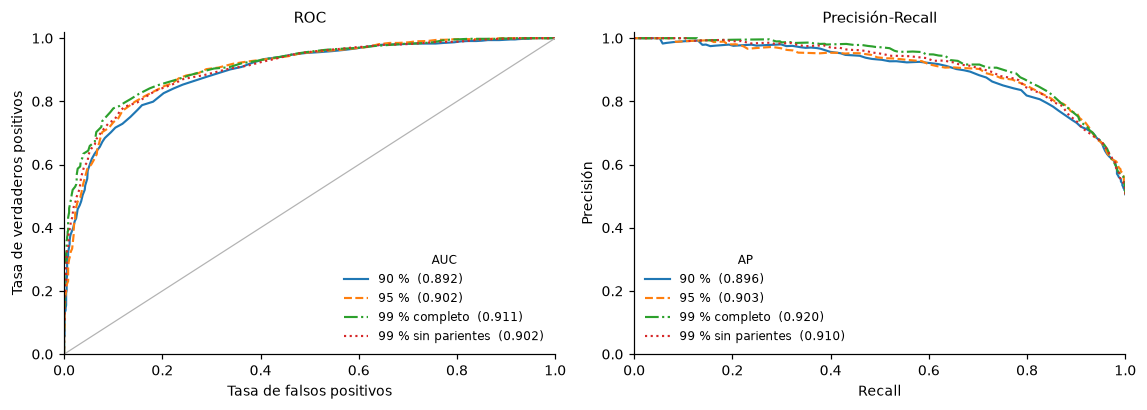

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 3.8))
estilos = ["-", "--", "-.", ":"]

for (e, d), est in zip(datos.items(), estilos):
    y = d["y"].to_numpy(dtype=int)
    p = d["p"].to_numpy(dtype=float)

    fpr, tpr, _ = roc_curve(y, p)
    ax1.plot(fpr, tpr, est, linewidth=1.4, label=f"{e}  ({roc_auc_score(y, p):.3f})")

    pre, rec, _ = precision_recall_curve(y, p)
    ax2.plot(rec, pre, est, linewidth=1.4,
             label=f"{e}  ({average_precision_score(y, p):.3f})")

ax1.plot([0, 1], [0, 1], color="0.7", linewidth=0.8)
ax1.set_xlabel("Tasa de falsos positivos")
ax1.set_ylabel("Tasa de verdaderos positivos")
ax1.set_title("ROC", fontsize=10)
ax1.legend(frameon=False, loc="lower right", fontsize=8, title="AUC", title_fontsize=8)

ax2.set_xlabel("Recall")
ax2.set_ylabel("Precisión")
ax2.set_title("Precisión-Recall", fontsize=10)
ax2.legend(frameon=False, loc="lower left", fontsize=8, title="AP", title_fontsize=8)

for ax in (ax1, ax2):
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)

fig.tight_layout()
fig.savefig(RES / "curvas_id95_vs_id99.png", dpi=200, bbox_inches="tight")
plt.show()

Las líneas van con trazo distinto además de color distinto, para que la figura se
siga leyendo si el documento se imprime en blanco y negro.

## 3. Comparación a igual recall

Comparar dos modelos a umbral fijo es engañoso cuando sus distribuciones de
probabilidad están corridas: uno puede parecer peor solo porque el 0.5 le cae en
otro punto de su curva.

La comparación justa es ponerlos a cazar la misma proporción de genes reales y
ver cuál ensucia menos. Aquí se toma el recall que da el modelo del 95 % a 0.5, y
se busca qué umbral necesita cada uno de los otros para llegar al mismo recall.

In [7]:
REFERENCIA = "95 %" if "95 %" in datos else next(iter(datos))
objetivo = metricas(datos[REFERENCIA])["recall"]
print(f"Referencia: {REFERENCIA} a umbral 0.50 -> recall {objetivo:.3f}\n")


def a_recall(d, meta):
    # Umbral más alto que todavía alcanza `meta` de recall.
    y = d["y"].to_numpy(dtype=int)
    p = d["p"].to_numpy(dtype=float)
    pre, rec, umb = precision_recall_curve(y, p)
    pre, rec = pre[:-1], rec[:-1]
    viable = rec >= meta
    if not viable.any():
        return None
    i = int(np.argmax(np.where(viable, pre, -1)))
    return float(umb[i])


filas = {}
for e, d in datos.items():
    t = a_recall(d, objetivo)
    if t is None:
        print(f"  {e}: no alcanza ese recall con ningún umbral")
        continue
    m = metricas(d, t)
    m["umbral"] = t
    filas[e] = m

igual = pd.DataFrame(filas).T[["umbral", "recall", "precision", "F1", "FP", "FN", "marcados"]]
igual[["FP", "FN", "marcados"]] = igual[["FP", "FN", "marcados"]].astype(int)
igual.round(3)

Referencia: 95 % a umbral 0.50 -> recall 0.889



,umbral,recall,precision,F1,FP,FN,marcados
90 %,0.50,0.892,0.741,0.809,312,108,1204
95 %,0.50,0.889,0.769,0.825,267,111,1156
99 % completo,0.44,0.893,0.767,0.825,272,107,1165
99 % sin parientes,0.45,0.896,0.743,0.812,310,104,1206


In [8]:
ref = metricas(datos[REFERENCIA])
for e, m in filas.items():
    if e == REFERENCIA:
        continue
    dp = m["precision"] - ref["precision"]
    print(f"{REFERENCIA} vs {e}, los dos a recall ~{objetivo:.3f}")
    print(f"  precisión       {ref['precision']:.3f} -> {m['precision']:.3f}   ({dp:+.3f})")
    print(f"  falsas alarmas  {int(ref['FP']):,} -> {int(m['FP']):,}")
    if dp > 0.02:
        print("  -> a igual recall ensucia menos: la ganancia existía y estaba")
        print("     escondida por el umbral.")
    elif dp < -0.02:
        print("  -> a igual recall ensucia más.")
    else:
        print("  -> equivalentes: subir la identidad no cambió la capacidad de")
        print("     distinguir, solo movió el punto de operación.")
    print()

95 % vs 90 %, los dos a recall ~0.889
  precisión       0.769 -> 0.741   (-0.028)
  falsas alarmas  267 -> 312
  -> a igual recall ensucia más.

95 % vs 99 % completo, los dos a recall ~0.889
  precisión       0.769 -> 0.767   (-0.003)
  falsas alarmas  267 -> 272
  -> equivalentes: subir la identidad no cambió la capacidad de
     distinguir, solo movió el punto de operación.

95 % vs 99 % sin parientes, los dos a recall ~0.889
  precisión       0.769 -> 0.743   (-0.026)
  falsas alarmas  267 -> 310
  -> a igual recall ensucia más.



## 4. Barrido del umbral

La columna `marcados` es el número que se ve en la GUI. Este cuadro sirve para
elegir `UMBRAL_DEFECTO` en `app/argus_gui.py` viendo qué cuesta moverse en cada
dirección.

In [9]:
ELEGIDO = "99 % completo" if "99 % completo" in datos else next(iter(datos))
d = datos[ELEGIDO]

barrido = []
for t in np.arange(0.20, 0.76, 0.05):
    m = metricas(d, float(t))
    barrido.append({
        "umbral": round(float(t), 2),
        "marcados": int(m["marcados"]),
        "aciertos": int(m["marcados"] - m["FP"]),
        "falsas alarmas": int(m["FP"]),
        "se escapan": int(m["FN"]),
        "recall": m["recall"],
        "precision": m["precision"],
        "F1": m["F1"],
    })

barrido = pd.DataFrame(barrido).set_index("umbral")
print(f"Modelo: {ELEGIDO}\n")
barrido.round(3)

Modelo: 99 % completo



,marcados,aciertos,falsas alarmas,se escapan,recall,precision,F1
umbral,,,,,,,
0.20,1952,1000,952,0,1.000,0.512,0.678
0.25,1937,1000,937,0,1.000,0.516,0.681
0.30,1870,999,871,1,0.999,0.534,0.696
0.35,1703,985,718,15,0.985,0.578,0.729
0.40,1444,957,487,43,0.957,0.663,0.783
0.45,1096,870,226,130,0.870,0.794,0.830
0.50,839,754,85,246,0.754,0.899,0.820
0.55,642,609,33,391,0.609,0.949,0.742
0.60,498,485,13,515,0.485,0.974,0.648


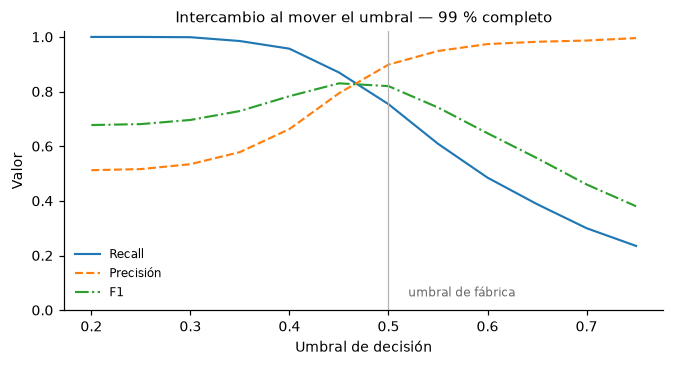

In [10]:
fig, ax = plt.subplots(figsize=(6.2, 3.4))
ax.plot(barrido.index, barrido["recall"], "-", linewidth=1.4, label="Recall")
ax.plot(barrido.index, barrido["precision"], "--", linewidth=1.4, label="Precisión")
ax.plot(barrido.index, barrido["F1"], "-.", linewidth=1.4, label="F1")
ax.axvline(0.5, color="0.7", linewidth=0.8)
ax.annotate("umbral de fábrica", xy=(0.5, 0.05), xytext=(0.52, 0.05), fontsize=8, color="0.4")
ax.set_xlabel("Umbral de decisión")
ax.set_ylabel("Valor")
ax.set_ylim(0, 1.02)
ax.legend(frameon=False, fontsize=8, loc="lower left")
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
ax.set_title(f"Intercambio al mover el umbral — {ELEGIDO}", fontsize=10)
fig.tight_layout()
fig.savefig(RES / "barrido_umbral_id99.png", dpi=200, bbox_inches="tight")
plt.show()

Las dos líneas se cruzan: no hay un umbral que mejore recall y precisión al mismo
tiempo. Bajarlo hace que el sistema marque más genes, atrapando más resistencias
reales pero también más falsas alarmas; subirlo hace lo contrario.

Dónde pararse no lo decide una métrica, lo decide el uso. En una herramienta de
tamizaje con revisión posterior, un falso positivo cuesta el tiempo de alguien
verificando; un falso negativo es un gen de resistencia que nadie vuelve a mirar.
No cuestan lo mismo.

## 5. Etapa 2 — modelo de familias

Aquí el efecto del 99 % es de otra naturaleza. No se trata de acertar más sobre
lo mismo, sino de que hay familias que **antes no se podían modelar** porque no
juntaban el mínimo de 30 genes.

In [11]:
metas = {
    "RandomForest": RES / "familias" / "modelo_familias_meta.json",
    "DNABERT-6":    RES / "familias" / "familias_dnabert_meta.json",
}

resumen = {}
for nombre, ruta in metas.items():
    if not ruta.exists():
        print(f"  falta {ruta.name}")
        continue
    m = json.loads(ruta.read_text(encoding="utf-8"))
    resumen[nombre] = {
        "clases": len(m.get("clases", [])),
        "genes": m.get("n_genes"),
        "balanced acc (gen)": m.get("test_gen_balanced_acc"),
        "F1 macro (gen)": m.get("test_gen_f1_macro"),
        "min_pb": m.get("min_pb"),
        "relleno": m.get("relleno"),
    }

pd.DataFrame(resumen).T

,clases,genes,balanced acc (gen),F1 macro (gen),min_pb,relleno
RandomForest,17,1932,0.721834,0.713819,150,ninguno
DNABERT-6,17,1932,0.735611,0.670837,150,ninguno


Las dos filas tienen que coincidir en `min_pb` y `relleno`. Si no coinciden, los
modelos vieron fragmentos distintos y la comparación no es directa: habría que
reentrenar el que esté desalineado antes de reportar la diferencia.

In [12]:
ruta_fam = RES / "familias" / "etiquetas_finales.tsv"
if ruta_fam.exists():
    fam = pd.read_csv(ruta_fam, sep="\t")
    col = fam.columns[-1]
    censo = fam[col].value_counts()
    print(f"{len(censo)} familias | {len(fam):,} genes etiquetados\n")
    print(censo.to_string())
else:
    print("No encontré etiquetas_finales.tsv")

4 familias | 2,208 genes etiquetados

n_crudas
1    2083
2     115
3       9
4       1


Las familias que aparecieron al subir a 99 % y que antes quedaban por debajo del
mínimo son carbapenemasa (IMP/VIM/NDM/KPC), qnr quinolonas, beta-lactamasa de
espectro extendido, MCR fosfoetanolamina transferasa y ANT nucleotidiltransferasa.

Son clínicamente relevantes: las carbapenemasas y las ESBL son de los mecanismos
que más preocupan en infecciones hospitalarias, y MCR es el de resistencia a
colistina, que es antibiótico de último recurso. Poder nombrarlas, aunque sea con
pocos ejemplos, vale más que un par de centésimas en una métrica global.

## 6. Qué se concluye

La celda siguiente arma el resumen con los números que se acaban de calcular, en
lugar de dejarlos escritos a mano, para que siga siendo cierto si el notebook se
vuelve a correr con datos nuevos.

In [13]:
print("=" * 78)
print("RESUMEN")
print("=" * 78)

if "95 %" in datos and "99 % completo" in datos:
    a, b = metricas(datos["95 %"]), metricas(datos["99 % completo"])
    print(f"\nEtapa 1, de 95 % a 99 % (umbral 0.5):")
    print(f"  recall    {a['recall']:.3f} -> {b['recall']:.3f}")
    print(f"  precisión {a['precision']:.3f} -> {b['precision']:.3f}")
    print(f"  F1        {a['F1']:.3f} -> {b['F1']:.3f}")
    print(f"  AUC       {a['AUC']:.3f} -> {b['AUC']:.3f}")

if "99 % completo" in datos and "99 % sin parientes" in datos:
    a, b = metricas(datos["99 % completo"]), metricas(datos["99 % sin parientes"])
    print(f"\nCuánto de eso era fuga por variantes casi idénticas:")
    print(f"  AUC {a['AUC']:.3f} (completo) -> {b['AUC']:.3f} (sin parientes)")
    if "95 %" in datos:
        c = metricas(datos["95 %"])
        print(f"      contra {c['AUC']:.3f} del 95 %")
        if abs(b["AUC"] - c["AUC"]) < 0.015:
            print("  Al quitar los parientes el AUC vuelve al del 95 %: la ventaja")
            print("  del conjunto completo era contaminación, no aprendizaje.")

if resumen:
    print("\nEtapa 2:")
    for nombre, r in resumen.items():
        print(f"  {nombre:<14} {r['clases']} clases, balanced acc "
              f"{r['balanced acc (gen)']:.3f}")
    print("  Subir a 99 % no se justifica por la métrica global sino por")
    print("  cobertura: cinco familias que antes no alcanzaban el mínimo.")
print("\n" + "=" * 78)

RESUMEN

Etapa 1, de 95 % a 99 % (umbral 0.5):
  recall    0.889 -> 0.754
  precisión 0.769 -> 0.899
  F1        0.825 -> 0.820
  AUC       0.902 -> 0.911

Cuánto de eso era fuga por variantes casi idénticas:
  AUC 0.911 (completo) -> 0.902 (sin parientes)
      contra 0.902 del 95 %
  Al quitar los parientes el AUC vuelve al del 95 %: la ventaja
  del conjunto completo era contaminación, no aprendizaje.

Etapa 2:
  RandomForest   17 clases, balanced acc 0.722
  DNABERT-6      17 clases, balanced acc 0.736
  Subir a 99 % no se justifica por la métrica global sino por
  cobertura: cinco familias que antes no alcanzaban el mínimo.



---

La lectura corta: **el conjunto al 99 % valió la pena por la etapa 2, no por la
etapa 1.** En detección binaria el modelo no distingue mejor, solo quedó parado
en un punto más conservador de la misma curva. En clasificación de familias sí
hay una ganancia real, y no es un decimal: son cinco mecanismos de resistencia
que el sistema antes no podía nombrar.

Tiene sentido biológico. Conservar más variantes alélicas de una misma familia le
enseña al clasificador cómo varía esa familia por dentro, que es justo lo que
necesita para reconocerla. Al detector binario no le dice nada nuevo sobre qué
separa un gen de resistencia de uno que no lo es, porque de cada grupo ya tenía
un representante.

Modelo: argus_rf_k6_id99_v2.joblib
  fragmentación: opcion D: descartar < 150 pb reales, sin padding
  min_pb 150 | relleno ninguno | identidad 99 %

2,000 genes del 1k+1k -> 4,078 fragmentos
  pos 1,915 | neg 2,163
  no evaluables (< 150 pb): 23

=== 1k+1k (por fragmento, umbral 0.5) ===
Matriz de confusión:
                Predijo NEG  Predijo POS
  Real NEG (0)        2,052          111
  Real POS (1)          656        1,259

               precision    recall  f1-score   support

no_resist (0)      0.758     0.949     0.843      2163
   resist (1)      0.919     0.657     0.767      1915

     accuracy                          0.812      4078
    macro avg      0.838     0.803     0.805      4078
 weighted avg      0.833     0.812     0.807      4078

AUC-ROC: 0.906


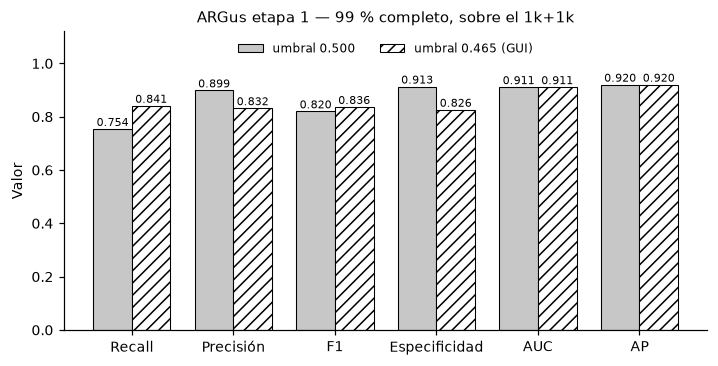

Genes marcados como resistentes: 839 a 0.500  |  1,011 a 0.465   (reales: 1,000)


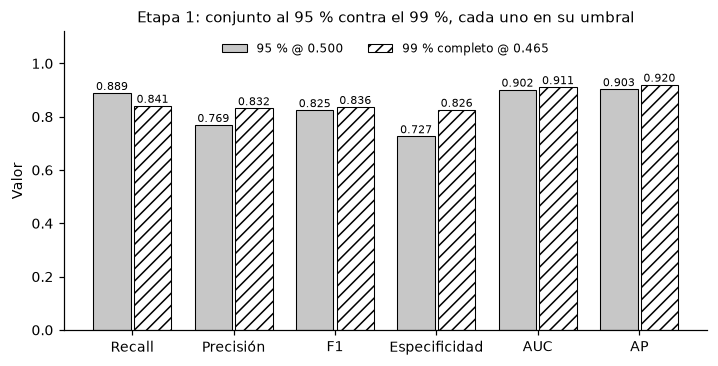

configuración             marcados  aciertos  falsas al.  se escapan
95 % @ 0.500                 1,156       889         267         111
99 % completo @ 0.465        1,011       841         170         159
(positivos reales)           1,000


In [17]:
# ============================================================================
#  CELDAS PARA 03_comparacion_id95_vs_id99.ipynb
#
#  Tres celdas. Cada bloque entre marcas "# %% CELDA n" va en su propia celda.
#  Suponen que ya corrieron las celdas 0 y 1 del notebook (RAIZ, RES, datos,
#  metricas, np, pd, plt ya existen).
# ============================================================================


# %% CELDA A -- markdown
"""
## 7. Reporte por fragmento sobre el 1k+1k

Las métricas de arriba son por gen: se juntan los fragmentos de un gen y se
decide una vez. Aquí se baja un nivel y se evalúa **cada fragmento por
separado**, que es donde se ve de verdad qué tan bien separa el modelo.

Se usa el conjunto 1k+1k en lugar de la partición interna de entrenamiento. Es
un conjunto más exigente: ninguno de sus genes entró al entrenamiento de ninguna
de las corridas, mientras que la partición interna cambia de una corrida a otra.
Por eso estos números no coinciden con los del notebook 02, y está bien que no
coincidan: son conjuntos distintos.
"""


# %% CELDA A -- código
import joblib
from itertools import product
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# ------------------------------------------------------------------ parámetros
MODELO = RAIZ / "data" / "models" / "argus_rf_k6_id99_v2.joblib"
FASTA_1K1K = RAIZ / "data" / "interim" / "muestra_genes_completos.fasta"
LABELS_1K1K = RAIZ / "data" / "interim" / "muestra_genes_labels.tsv"
K_MER, VENTANA, MIN_PB, UMBRAL = 6, 500, 150, 0.5

for p in (MODELO, FASTA_1K1K, LABELS_1K1K):
    assert p.exists(), f"falta {p}"


# ------------------------------------------------------------------ utilidades
def fragmentar(seq, ventana=VENTANA, min_pb=MIN_PB):
    """Misma regla con la que se entrenó: bloques de `ventana`, el resto final
    se conserva con su largo real si llega a `min_pb`, y se descarta si no.
    Nunca rellena ni solapa. Un gen más corto que `min_pb` devuelve []."""
    seq = seq.upper()
    L = len(seq)
    if L < ventana:
        return [seq] if L >= min_pb else []
    n = L // ventana
    fr = [seq[i * ventana:(i + 1) * ventana] for i in range(n)]
    if L - n * ventana >= min_pb:
        fr.append(seq[n * ventana:])
    return fr


_LUT = np.full(256, 4, dtype=np.int8)
for _i, _b in enumerate(b"ACGT"):
    _LUT[_b] = _i
_POT = (4 ** np.arange(K_MER - 1, -1, -1)).astype(np.int64)


def vector_kmer(seq):
    """Frecuencia de k-meros, ignorando toda ventana que toque algo que no sea
    ACGT. Idéntica a la del entrenamiento y a la de la GUI."""
    a = _LUT[np.frombuffer(seq.upper().encode("ascii", "replace"), dtype=np.uint8)]
    out = np.zeros(4 ** K_MER, dtype=np.float32)
    if len(a) - K_MER + 1 <= 0:
        return out
    win = np.lib.stride_tricks.sliding_window_view(a, K_MER)
    ok = (win < 4).all(axis=1)
    if not ok.any():
        return out
    idx = (win[ok].astype(np.int64) * _POT).sum(axis=1)
    out += np.bincount(idx, minlength=4 ** K_MER).astype(np.float32)
    return out / out.sum()


def leer_fasta(p):
    d, h, s = {}, None, []
    with open(p, encoding="utf-8", errors="replace") as fh:
        for l in fh:
            l = l.rstrip("\n")
            if l.startswith(">"):
                if h:
                    d[h] = "".join(s)
                h, s = l[1:].split()[0], []
            else:
                s.append(l.strip())
    if h:
        d[h] = "".join(s)
    return d


# ------------------------------------------------------------------ cargar
_m = joblib.load(MODELO)
modelo = _m["modelo"] if isinstance(_m, dict) else _m
assert modelo.n_features_in_ == 4 ** K_MER, "el modelo no espera vectores de k=6"

if isinstance(_m, dict):
    print(f"Modelo: {MODELO.name}")
    print(f"  fragmentación: {_m.get('fragmentacion', 'sin registrar')}")
    print(f"  min_pb {_m.get('min_pb')} | relleno {_m.get('relleno')} "
          f"| identidad {_m.get('identidad')} %")
    assert _m.get("min_pb") == MIN_PB, (
        f"el modelo se entrenó con min_pb={_m.get('min_pb')} y aquí se usa {MIN_PB}: "
        "los fragmentos no serían los mismos")

secs = leer_fasta(FASTA_1K1K)
lab = pd.read_csv(LABELS_1K1K, sep="\t")
y_gen = dict(zip(lab.iloc[:, 0].astype(str), lab.iloc[:, 1].astype(int)))

# ------------------------------------------------------------------ fragmentar
seqs, y_frag, gid_frag, no_evaluables = [], [], [], []
for gid, etiqueta in y_gen.items():
    s = secs.get(gid)
    if s is None:
        continue
    fr = fragmentar(s)
    if not fr:
        no_evaluables.append(gid)
        continue
    seqs.extend(fr)
    y_frag.extend([etiqueta] * len(fr))
    gid_frag.extend([gid] * len(fr))

y_frag = np.array(y_frag, dtype=int)
X = np.vstack([vector_kmer(s) for s in seqs])

print(f"\n{len(y_gen):,} genes del 1k+1k -> {len(y_frag):,} fragmentos")
print(f"  pos {int((y_frag == 1).sum()):,} | neg {int((y_frag == 0).sum()):,}")
print(f"  no evaluables (< {MIN_PB} pb): {len(no_evaluables)}")
assert not any("0" in s for s in seqs[:5000]), "quedó relleno con ceros"

# ------------------------------------------------------------------ evaluar
p_frag = modelo.predict_proba(X)[:, 1]
yhat = (p_frag >= UMBRAL).astype(int)

cm = confusion_matrix(y_frag, yhat)
print(f"\n=== 1k+1k (por fragmento, umbral {UMBRAL}) ===")
print("Matriz de confusión:")
print("                Predijo NEG  Predijo POS")
print(f"  Real NEG (0)  {cm[0, 0]:>11,}  {cm[0, 1]:>11,}")
print(f"  Real POS (1)  {cm[1, 0]:>11,}  {cm[1, 1]:>11,}")
print()
print(classification_report(y_frag, yhat, digits=3,
                            target_names=["no_resist (0)", "resist (1)"]))
print(f"AUC-ROC: {roc_auc_score(y_frag, p_frag):.3f}")


# %% CELDA B -- markdown
"""
## 8. El modelo del 99 % en una vista

Las cinco métricas del modelo elegido sobre el 1k+1k, a nivel gen. Recall y
precisión se mueven en sentidos contrarios al cambiar el umbral; AUC y AP no
dependen de él.
"""


# %% CELDA B -- código
ELEGIDO = "99 % completo"
UMBRAL_GUI = 0.465      # el que quedó en app/argus_gui.py

m05 = metricas(datos[ELEGIDO], 0.5)
mgui = metricas(datos[ELEGIDO], UMBRAL_GUI)

orden = ["recall", "precision", "F1", "especificidad", "AUC", "AP"]
etiquetas = ["Recall", "Precisión", "F1", "Especificidad", "AUC", "AP"]

fig, ax = plt.subplots(figsize=(6.6, 3.4))
x = np.arange(len(orden))
ancho = 0.38

b1 = ax.bar(x - ancho / 2, [m05[k] for k in orden], ancho,
            label="umbral 0.500", color="0.78", edgecolor="black", linewidth=0.7)
b2 = ax.bar(x + ancho / 2, [mgui[k] for k in orden], ancho,
            label=f"umbral {UMBRAL_GUI:.3f} (GUI)", color="white",
            edgecolor="black", linewidth=0.7, hatch="///")

for barras in (b1, b2):
    for b in barras:
        ax.annotate(f"{b.get_height():.3f}",
                    xy=(b.get_x() + b.get_width() / 2, b.get_height()),
                    xytext=(0, 2), textcoords="offset points",
                    ha="center", fontsize=7.5)

ax.set_xticks(x)
ax.set_xticklabels(etiquetas)
ax.set_ylim(0, 1.12)
ax.set_ylabel("Valor")
ax.set_title(f"ARGus etapa 1 — {ELEGIDO}, sobre el 1k+1k", fontsize=10)
ax.legend(frameon=False, fontsize=8, ncol=2, loc="upper center")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
fig.savefig(RES / "barras_id99.png", dpi=200, bbox_inches="tight")
plt.show()

print(f"Genes marcados como resistentes: {int(m05['marcados']):,} a 0.500  |  "
      f"{int(mgui['marcados']):,} a {UMBRAL_GUI:.3f}   (reales: 1,000)")


# %% CELDA C -- markdown
"""
## 9. El modelo nuevo contra el que veníamos usando

Las dos configuraciones lado a lado, cada una en su umbral de operación: el del
95 % en 0.5, que es con el que se midió en el capítulo, y el del 99 % en el
umbral al que quedó la GUI.

Leer las barras de a pares, no la altura suelta: lo que gana una en precisión lo
paga en recall. La única comparación que no depende de dónde esté el umbral es
el par de AUC y AP.
"""


# %% CELDA C -- código
PAREJA = [("95 %", 0.5), ("99 % completo", UMBRAL_GUI)]

vals = {}
for etiqueta, t in PAREJA:
    if etiqueta not in datos:
        print(f"  falta {etiqueta}: se omite")
        continue
    vals[f"{etiqueta} @ {t:.3f}"] = metricas(datos[etiqueta], t)

fig, ax = plt.subplots(figsize=(6.6, 3.4))
x = np.arange(len(orden))
ancho = 0.8 / max(len(vals), 1)
relleno = [dict(color="0.78", hatch=""), dict(color="white", hatch="///")]

for i, (nombre, m) in enumerate(vals.items()):
    pos = x - 0.4 + ancho * (i + 0.5)
    barras = ax.bar(pos, [m[k] for k in orden], ancho * 0.92, label=nombre,
                    edgecolor="black", linewidth=0.7, **relleno[i % 2])
    for b in barras:
        ax.annotate(f"{b.get_height():.3f}",
                    xy=(b.get_x() + b.get_width() / 2, b.get_height()),
                    xytext=(0, 2), textcoords="offset points",
                    ha="center", fontsize=7.5)

ax.set_xticks(x)
ax.set_xticklabels(etiquetas)
ax.set_ylim(0, 1.12)
ax.set_ylabel("Valor")
ax.set_title("Etapa 1: conjunto al 95 % contra el 99 %, cada uno en su umbral",
             fontsize=10)
ax.legend(frameon=False, fontsize=8, ncol=2, loc="upper center")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
fig.savefig(RES / "barras_id95_vs_id99.png", dpi=200, bbox_inches="tight")
plt.show()

print(f"{'configuración':<24} {'marcados':>9} {'aciertos':>9} "
      f"{'falsas al.':>11} {'se escapan':>11}")
for nombre, m in vals.items():
    print(f"{nombre:<24} {int(m['marcados']):>9,} "
          f"{int(m['marcados'] - m['FP']):>9,} {int(m['FP']):>11,} "
          f"{int(m['FN']):>11,}")
print(f"{'(positivos reales)':<24} {1000:>9,}")